In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "AEP_hourly.csv"

df = pd.read_csv(DATA_PATH)

df["Datetime"] = pd.to_datetime(df["Datetime"])
df = df.sort_values("Datetime").reset_index(drop=True)

df.head()

,Datetime,AEP_MW
0,2004-10-01 01:00:00,12379.0
1,2004-10-01 02:00:00,11935.0
2,2004-10-01 03:00:00,11692.0
3,2004-10-01 04:00:00,11597.0
4,2004-10-01 05:00:00,11681.0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 121273 entries, 0 to 121272
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  121273 non-null  datetime64[us]
 1   AEP_MW    121273 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 1.9 MB


In [6]:
df["AEP_MW"].describe()

count    121273.000000
mean      15499.513717
std        2591.399065
min        9581.000000
25%       13630.000000
50%       15310.000000
75%       17200.000000
max       25695.000000
Name: AEP_MW, dtype: float64

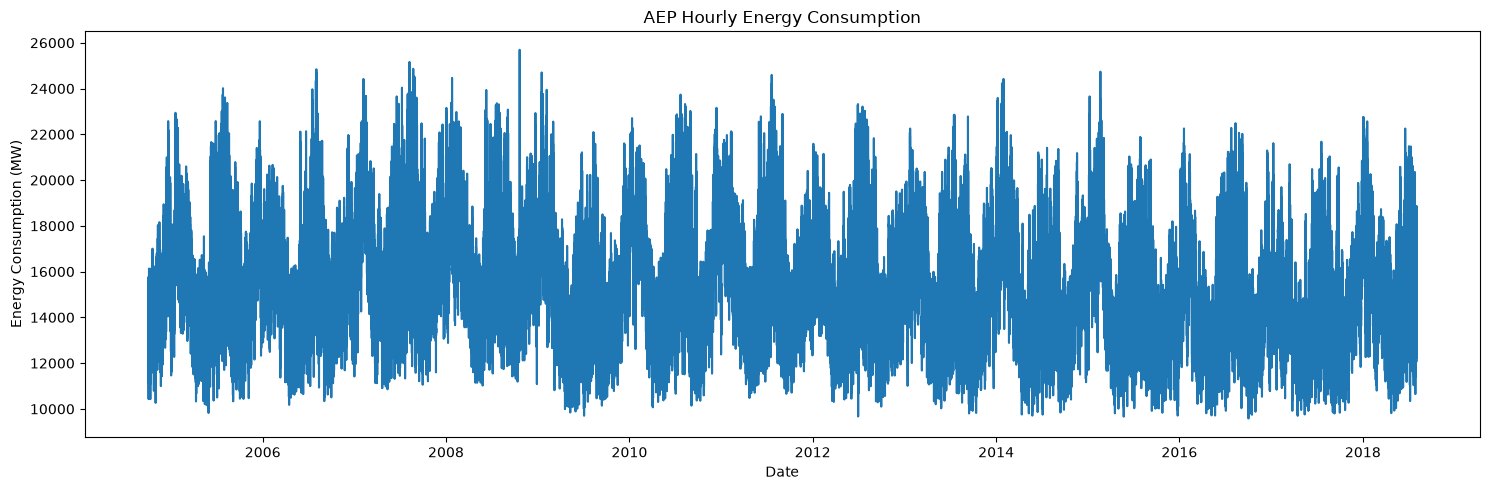

In [7]:
plt.figure(figsize=(15, 5))

plt.plot(df["Datetime"], df["AEP_MW"])

plt.title("AEP Hourly Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (MW)")

plt.tight_layout()
plt.show()

In [8]:
df["Hour"] = df["Datetime"].dt.hour
df["DayOfWeek"] = df["Datetime"].dt.dayofweek
df["Month"] = df["Datetime"].dt.month
df["Year"] = df["Datetime"].dt.year

df.head()

,Datetime,AEP_MW,Hour,DayOfWeek,Month,Year
0,2004-10-01 01:00:00,12379.0,1,4,10,2004
1,2004-10-01 02:00:00,11935.0,2,4,10,2004
2,2004-10-01 03:00:00,11692.0,3,4,10,2004
3,2004-10-01 04:00:00,11597.0,4,4,10,2004
4,2004-10-01 05:00:00,11681.0,5,4,10,2004


In [9]:
df["Lag_1"] = df["AEP_MW"].shift(1)
df["Lag_2"] = df["AEP_MW"].shift(2)
df["Lag_24"] = df["AEP_MW"].shift(24)
df["Lag_168"] = df["AEP_MW"].shift(168)

df.head(30)

,Datetime,AEP_MW,Hour,DayOfWeek,Month,Year,Lag_1,Lag_2,Lag_24,Lag_168
0,2004-10-01 01:00:00,12379.0,1,4,10,2004,NaN,NaN,NaN,NaN
1,2004-10-01 02:00:00,11935.0,2,4,10,2004,12379.0,NaN,NaN,NaN
2,2004-10-01 03:00:00,11692.0,3,4,10,2004,11935.0,12379.0,NaN,NaN
3,2004-10-01 04:00:00,11597.0,4,4,10,2004,11692.0,11935.0,NaN,NaN
4,2004-10-01 05:00:00,11681.0,5,4,10,2004,11597.0,11692.0,NaN,NaN
5,2004-10-01 06:00:00,12280.0,6,4,10,2004,11681.0,11597.0,NaN,NaN
6,2004-10-01 07:00:00,13692.0,7,4,10,2004,12280.0,11681.0,NaN,NaN
7,2004-10-01 08:00:00,14618.0,8,4,10,2004,13692.0,12280.0,NaN,NaN
8,2004-10-01 09:00:00,14903.0,9,4,10,2004,14618.0,13692.0,NaN,NaN
9,2004-10-01 10:00:00,15118.0,10,4,10,2004,14903.0,14618.0,NaN,NaN


In [10]:
df["Target"] = df["AEP_MW"].shift(-1)

df[
    [
        "Datetime",
        "AEP_MW",
        "Lag_1",
        "Lag_24",
        "Lag_168",
        "Target"
    ]
].head(10)


,Datetime,AEP_MW,Lag_1,Lag_24,Lag_168,Target
0,2004-10-01 01:00:00,12379.0,NaN,NaN,NaN,11935.0
1,2004-10-01 02:00:00,11935.0,12379.0,NaN,NaN,11692.0
2,2004-10-01 03:00:00,11692.0,11935.0,NaN,NaN,11597.0
3,2004-10-01 04:00:00,11597.0,11692.0,NaN,NaN,11681.0
4,2004-10-01 05:00:00,11681.0,11597.0,NaN,NaN,12280.0
5,2004-10-01 06:00:00,12280.0,11681.0,NaN,NaN,13692.0
6,2004-10-01 07:00:00,13692.0,12280.0,NaN,NaN,14618.0
7,2004-10-01 08:00:00,14618.0,13692.0,NaN,NaN,14903.0
8,2004-10-01 09:00:00,14903.0,14618.0,NaN,NaN,15118.0
9,2004-10-01 10:00:00,15118.0,14903.0,NaN,NaN,15242.0


In [11]:
df_model = df.dropna().copy()

print("Model dataset shape:", df_model.shape)

Model dataset shape: (121104, 11)


In [12]:
split_index = int(len(df_model) * 0.8)

train = df_model.iloc[:split_index].copy()
test = df_model.iloc[split_index:].copy()

print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("\nTrain period:")
print(train["Datetime"].min(), "to", train["Datetime"].max())

print("\nTest period:")
print(test["Datetime"].min(), "to", test["Datetime"].max())


Train shape: (96883, 11)
Test shape: (24221, 11)

Train period:
2004-10-08 01:00:00 to 2015-10-28 18:00:00

Test period:
2015-10-28 19:00:00 to 2018-08-02 23:00:00


In [13]:
features = [
    "AEP_MW",
    "Hour",
    "DayOfWeek",
    "Month",
    "Year",
    "Lag_1",
    "Lag_2",
    "Lag_24",
    "Lag_168"
]

X_train = train[features]
y_train = train["Target"]

X_test = test[features]
y_test = test["Target"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (96883, 9)
y_train: (96883,)
X_test: (24221, 9)
y_test: (24221,)


In [14]:
print("First training row:")
print(X_train.iloc[0])

print("\nFirst test row:")
print(X_test.iloc[0])

print("\nFirst test target:")
print(y_test.iloc[0])

First training row:
AEP_MW       12468.0
Hour             1.0
DayOfWeek        4.0
Month           10.0
Year          2004.0
Lag_1        13271.0
Lag_2        14359.0
Lag_24       12484.0
Lag_168      12379.0
Name: 168, dtype: float64

First test row:
AEP_MW       14236.0
Hour            19.0
DayOfWeek        2.0
Month           10.0
Year          2015.0
Lag_1        13887.0
Lag_2        14069.0
Lag_24       15098.0
Lag_168      13773.0
Name: 97051, dtype: float64

First test target:
14565.0


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

baseline_pred = test["AEP_MW"]

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 407.7192931753437
Baseline RMSE: 525.6559738464981


In [16]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

print("Linear Regression")
print(f"MAE:  {lr_mae:.2f} MW")
print(f"RMSE: {lr_rmse:.2f} MW")

Linear Regression
MAE:  195.05 MW
RMSE: 267.26 MW


In [17]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

print("Random Forest")
print(f"MAE:  {rf_mae:.2f} MW")
print(f"RMSE: {rf_rmse:.2f} MW")

Random Forest
MAE:  129.79 MW
RMSE: 179.28 MW


In [18]:
from sklearn.ensemble import HistGradientBoostingRegressor

gb_model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))

print("HistGradientBoosting")
print(f"MAE:  {gb_mae:.2f} MW")
print(f"RMSE: {gb_rmse:.2f} MW")

HistGradientBoosting
MAE:  126.44 MW
RMSE: 169.65 MW


In [19]:
results = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression",
        "Random Forest",
        "HistGradientBoosting"
    ],
    "MAE": [
        baseline_mae,
        lr_mae,
        rf_mae,
        gb_mae
    ],
    "RMSE": [
        baseline_rmse,
        lr_rmse,
        rf_rmse,
        gb_rmse
    ]
})

results

,Model,MAE,RMSE
0,Persistence Baseline,407.719293,525.655974
1,Linear Regression,195.048931,267.262684
2,Random Forest,129.794077,179.281236
3,HistGradientBoosting,126.435674,169.654715


In [20]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=features
)

feature_importance.sort_values(ascending=False)

AEP_MW       0.955761
Hour         0.021100
Lag_1        0.010942
Lag_2        0.008063
Month        0.001339
DayOfWeek    0.001115
Lag_24       0.000667
Lag_168      0.000583
Year         0.000430
dtype: float64

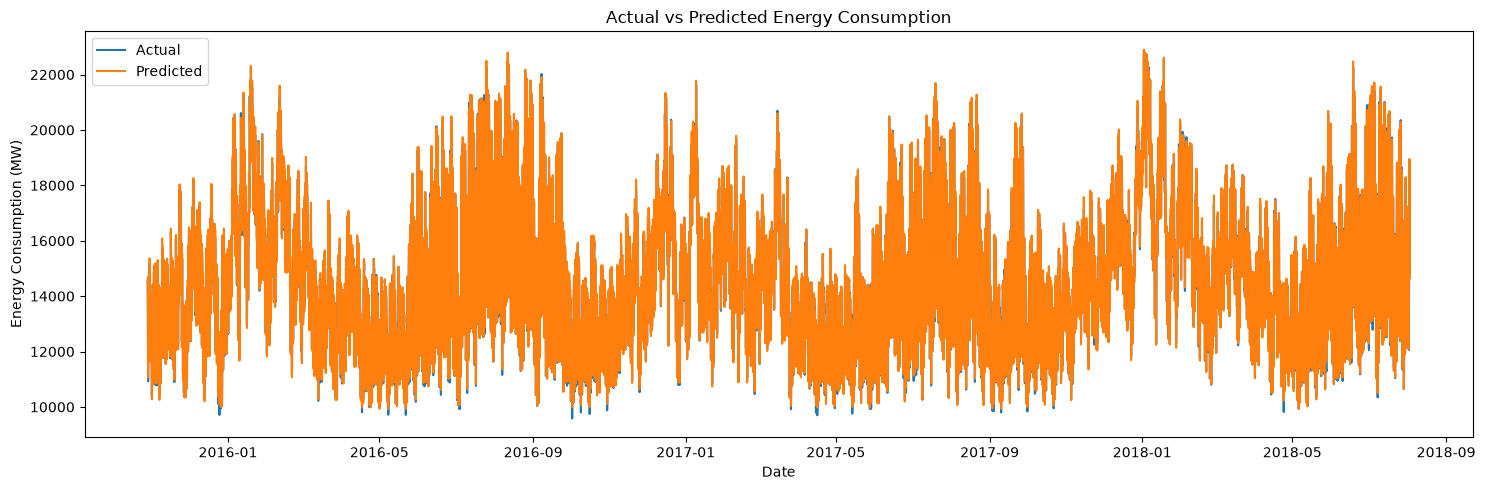

In [21]:
plt.figure(figsize=(15, 5))

plt.plot(test["Datetime"], y_test, label="Actual")
plt.plot(test["Datetime"], gb_pred, label="Predicted")

plt.title("Actual vs Predicted Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (MW)")

plt.legend()
plt.tight_layout()
plt.show()

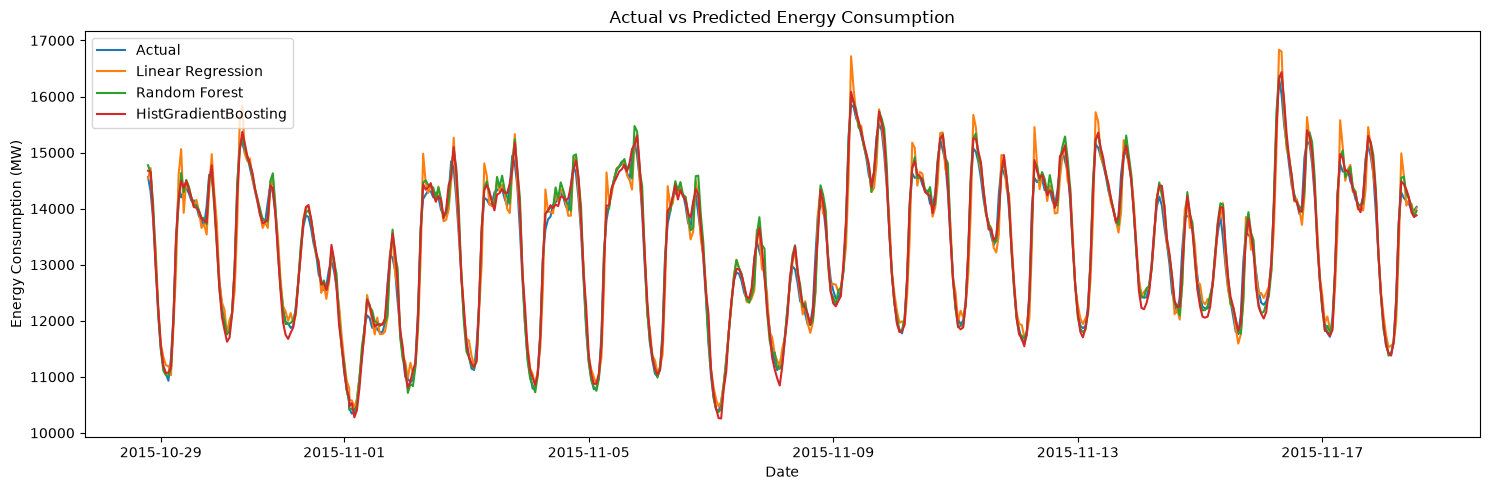

In [22]:
plt.figure(figsize=(15, 5))

plt.plot(
    test["Datetime"].iloc[:500],
    y_test.iloc[:500],
    label="Actual"
)

plt.plot(
    test["Datetime"].iloc[:500],
    lr_pred[:500],
    label="Linear Regression"
)

plt.plot(
    test["Datetime"].iloc[:500],
    rf_pred[:500],
    label="Random Forest"
)

plt.plot(
    test["Datetime"].iloc[:500],
    gb_pred[:500],
    label="HistGradientBoosting"
)

plt.title("Actual vs Predicted Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (MW)")
plt.legend()

plt.tight_layout()
plt.show()